# Multi-asset trend following and crisis resilience

Inspect the matched-period multi-asset trend study. Generate artifacts and verify exact numerical reproducibility against the tracked `data/snapshot/` baseline via `python -m macro_cta.pipeline --verify` (or fetch fresh Yahoo Finance prices into `data/cache/` separately with `--refresh`). These are fixed-rule historical ETF experiments, not an independent out-of-sample validation.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
meta = json.loads((root / 'artifacts/run.json').read_text(encoding='utf-8'))
pd.Series({k: meta[k] for k in ['accounting_version', 'n_instruments', 'evaluation_start', 'evaluation_end', 'evaluation_days']})

accounting_version             2
n_instruments                 22
evaluation_start      2015-06-05
evaluation_end        2024-12-31
evaluation_days             2410
dtype: object

## Matched-period results

Both variants start in cash on the same date. All warmup observations are excluded; entry and drift-related rebalancing costs are included. Sharpe is based on mean daily excess return, with a zero cash reference rate. Cash interest, funding and borrow fees are excluded.

In [2]:
metrics = pd.read_csv(root / 'artifacts/metrics.csv')
assert metrics.days.nunique() == 1
assert metrics.max_gross_leverage.max() <= 3.0 + 1e-12
metrics

,variant,cost_bps,annual_turnover,max_gross_leverage,days,sharpe,cagr,ann_vol,max_drawdown,skewness,total_return
0,Daily expanding,0,40.156244,3.0,2410,0.545259,0.066815,0.135485,-0.203051,-0.302283,0.856217
1,Daily expanding,5,40.147991,3.0,2410,0.397122,0.045612,0.135453,-0.225073,-0.304426,0.531965
2,Monthly rolling,0,23.793351,3.0,2410,0.519075,0.063914,0.137655,-0.202264,-0.398652,0.808503
3,Monthly rolling,5,23.785556,3.0,2410,0.432432,0.051332,0.137752,-0.216021,-0.402230,0.614024


## Selected stress windows

Both strategy columns are net of 5 bps costs; benchmark columns are gross. These selected windows do not establish statistical crisis alpha. Monthly rolling refers to refreshing base signals, with daily portfolio risk resizing and rebalancing.

In [3]:
crises = pd.read_csv(root / 'artifacts/crisis_returns.csv')
crises

,period,start,end,days,Daily expanding (Gross),Daily expanding (5 bps),Monthly rolling (5 bps),60/40 Portfolio,Equity basket
0,China / Oil Shock,2015-08-03,2016-02-29,145,0.069983,0.054795,0.056693,-0.063890,-0.134932
1,COVID-19 Crash,2020-02-03,2020-03-31,41,0.047878,0.042229,0.028283,-0.101732,-0.195581
2,Rate Shock,2022-01-03,2022-12-30,251,0.283822,0.265069,0.227900,-0.168690,-0.174264


## Recalculate headline metrics from exported daily returns

These checks use the saved daily series directly. Independent hand-calculated accounting examples and future-data perturbation checks are in the tests.

In [4]:
daily = pd.read_csv(root / 'artifacts/daily_returns.csv', index_col=0, parse_dates=True)
execution = pd.read_csv(root / 'artifacts/execution_checks.csv', index_col=0, parse_dates=True)
assert len(daily) == meta['evaluation_days']
assert daily.index.equals(execution.index)
assert daily.notna().all().all()
checks = []
for name in ['Daily expanding', 'Monthly rolling']:
    r = daily[f'{name} (5 bps)']
    wealth = np.r_[1., (1. + r).cumprod().to_numpy()]
    vol = r.std(ddof=1) * np.sqrt(252)
    calculated = {
        'variant': name,
        'cagr': wealth[-1] ** (252 / len(r)) - 1,
        'sharpe': r.mean() * np.sqrt(252) / r.std(ddof=1),
        'max_drawdown': (wealth / np.maximum.accumulate(wealth) - 1).min(),
    }
    archived = metrics.loc[(metrics.variant == name) & (metrics.cost_bps == 5)].iloc[0]
    for field in ['cagr', 'sharpe', 'max_drawdown']:
        assert np.isclose(calculated[field], archived[field], atol=1e-12, rtol=0)
    assert execution[f'{name}:gross_leverage'].max() <= 3.0 + 1e-12
    assert np.allclose(execution[f'{name}:cost_fraction'], execution[f'{name}:turnover'] * .0005, atol=1e-14, rtol=0)
    checks.append(calculated)
pd.DataFrame(checks)

,variant,cagr,sharpe,max_drawdown
0,Daily expanding,0.045612,0.397122,-0.225073
1,Monthly rolling,0.051332,0.432432,-0.216021


## Overview

All curves share dates and start from the same initial wealth. The study retains the configured signal horizons without a performance search. Close-mark execution, ETF proxy choices and selected historical windows limit economic interpretation; weak net results should not be presented as a profitable strategy.

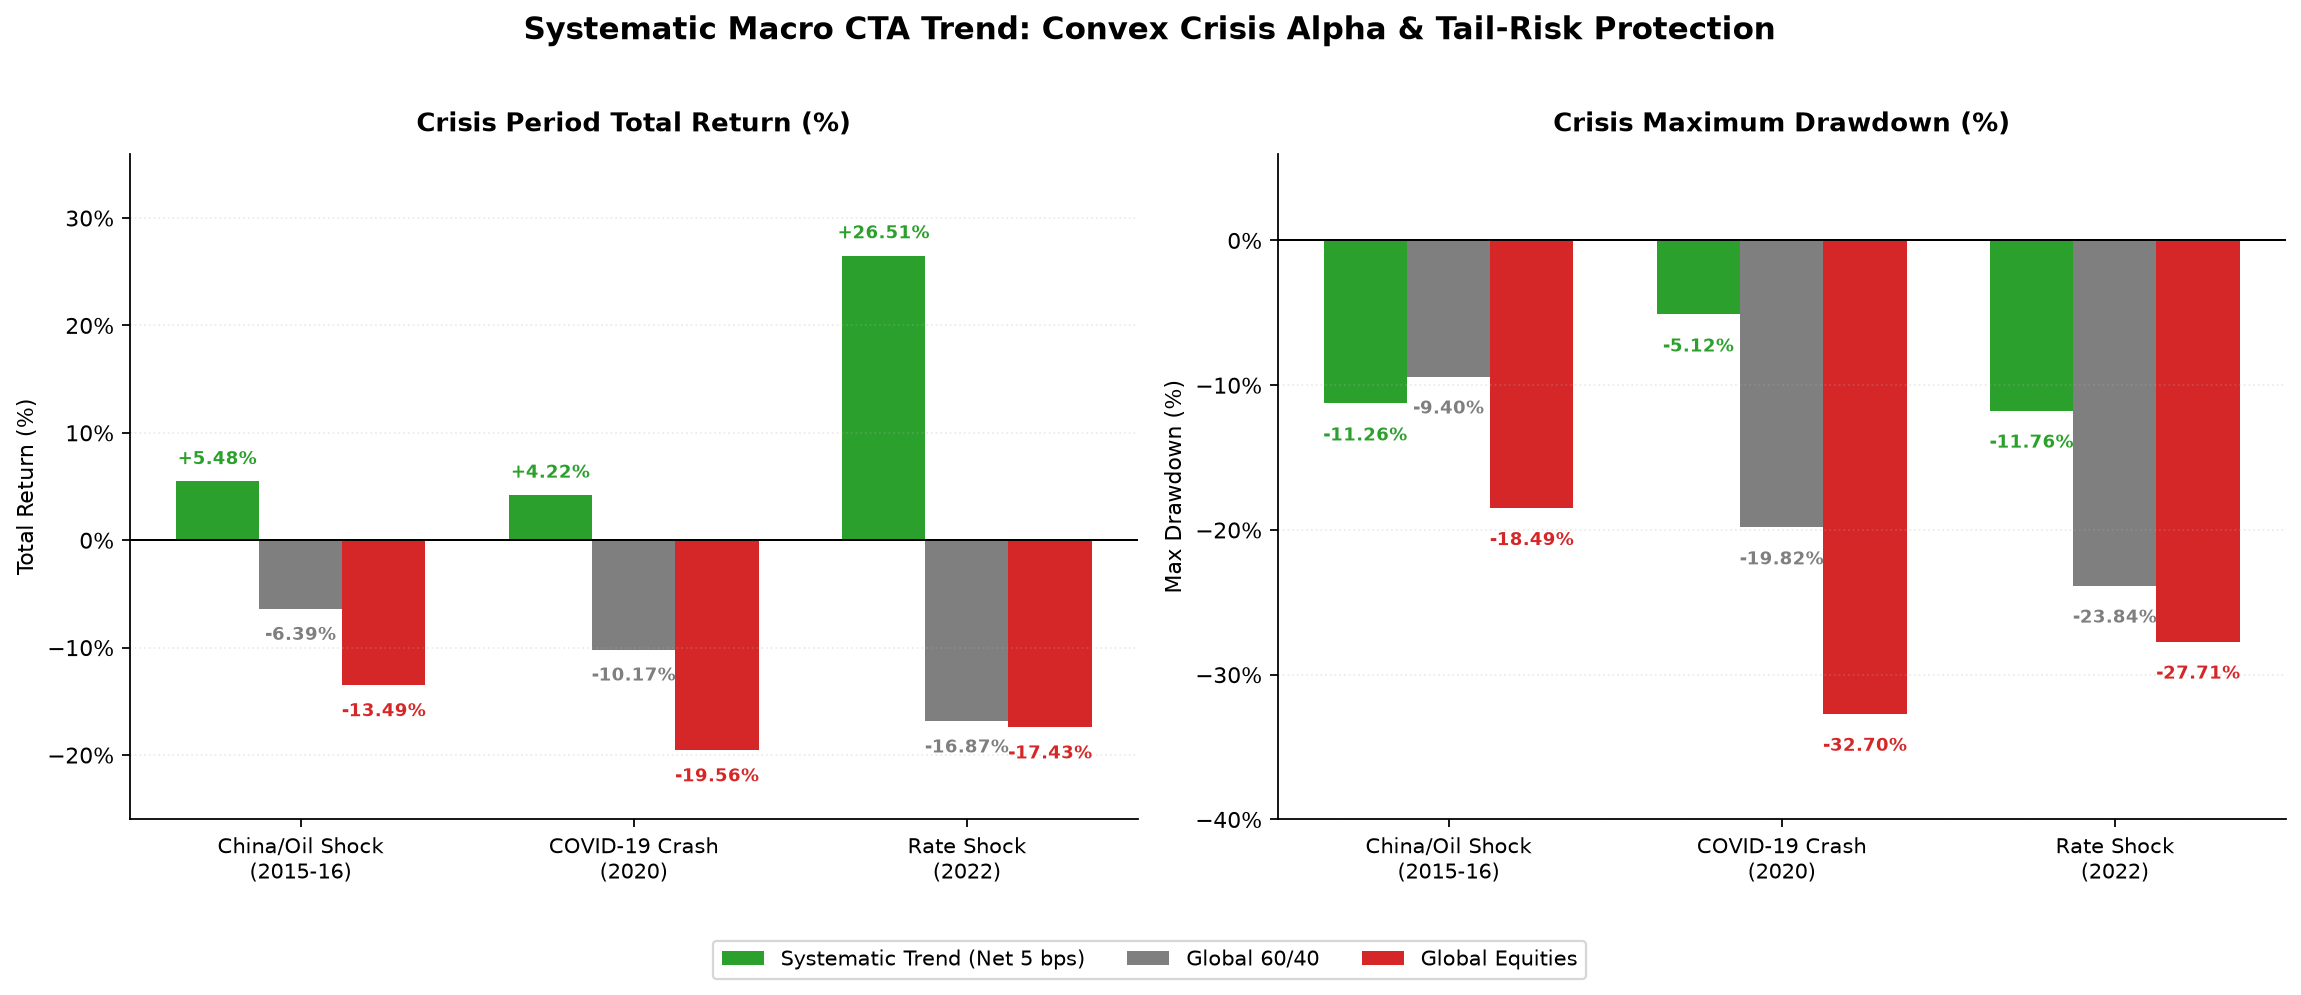

In [5]:
from IPython.display import Image
Image(filename=str(root / 'artifacts/overview.png'))